In [218]:
import pandas as pd
import numpy as np
import sqlite3
from tabulate import tabulate
from scipy import stats
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

warnings.filterwarnings("ignore")


## Section 1: Getting data 

In [219]:

url = "/Users/farhan/Downloads/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df_raw = pd.read_csv(url)

print("Dataset successfully loaded.")

Dataset successfully loaded.


In [220]:
print(f"Total Rows: {df_raw.shape[0]}")
print(f"Total Columns: {df_raw.shape[1]}")

Total Rows: 7043
Total Columns: 21


In [221]:
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [222]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Section 2. Data Quality Aduit

#### 2.1 Check Customer ID Integrity

In [223]:
# Count distinct customer IDs to verify primary key uniqueness
unique_ids = df_raw['customerID'].nunique()

# Compare unique customer IDs against total observations
print(f"Unique Customer IDs: {unique_ids}")
print(f"Matches Total Rows: {unique_ids == len(df_raw)}")

Unique Customer IDs: 7043
Matches Total Rows: True


#### 2.2 Check Duplicate Records

In [224]:
duplicate_rows = df_raw.duplicated().sum()

print(f"Duplicate Records: {duplicate_rows}")

Duplicate Records: 0


#### 2.3 Identify Hidden Missing Values

In [225]:
whitespace_mask = df_raw['TotalCharges'].str.isspace()

# Count the number of whitespace entries
whitespace_count = whitespace_mask.sum()

print(f"Whitespace Entries: {whitespace_count}")

Whitespace Entries: 11


## Section 3: Data Cleaning & Transformation

#### 3.1 Create a Working Copy

In [226]:
df_clean = df_raw.copy()

#### 3.2 Convert Total Charges to Numeric

In [227]:
# Since Total charge is an object let's convert into numeric for furthur use
df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'].replace(" ", np.nan)
)

#### 3.3 Handle Missing TotalCharges

In [228]:
# Assign zero accumulated charges to customers with missing TotalCharges. These records correspond to customers with zero tenure
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0.0)

#### 3.4 Standardize SeniorCitizen

In [229]:
# Convert binary numerical values into readable categorical labels
df_clean['SeniorCitizen'] = df_clean['SeniorCitizen'].map({
    0: 'No',
    1: 'Yes'
})

#### 3.5 Create a Binary Churn Target

In [230]:
# Encoding the churn outcome into a binary variable. 1 represents churned customers, while 0 represents retained customers
df_clean['Churn_Flag'] = df_clean['Churn'].map({
    'Yes': 1,
    'No': 0
})

In [231]:
df_clean.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Flag
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


## Section 4: Financial Data Integrity Validation

#### 4.1 Calculate Expected Total Charges

In [232]:
# accumulated charges using monthly charges multiplied by tenure
df_clean['expected_total_charges'] = (
    df_clean['MonthlyCharges'] * df_clean['tenure']
)

#### 4.2 Calculate Charge Variance

In [233]:
# absolute difference between actual and estimated charges
df_clean['charges_diff'] = np.abs(
    df_clean['TotalCharges'] - df_clean['expected_total_charges']
)


#### 4.3 Evaluate Financial Consistency

In [234]:
# Calculate the average absolute difference across all customer records
avg_variance = df_clean['charges_diff'].mean()

print(f"Average Absolute Charge Variance: ${avg_variance:.2f}")

Average Absolute Charge Variance: $45.02


In [235]:
df_clean.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Flag,expected_total_charges,charges_diff
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,29.85,0.00
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,One year,No,Mailed check,56.95,1889.50,No,0,1936.30,46.80
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,107.70,0.45
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,1903.50,62.75
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,141.40,10.25


## Section 5: Final Data Validation

#### 5.1 Check Remaining Missing Values

In [236]:

missing_values = df_clean.isnull().sum()

print("Missing Values by Column:")
print(missing_values[missing_values > 0])
print(f"\nTotal Missing Values: {df_clean.isnull().sum().sum()}")

Missing Values by Column:
Series([], dtype: int64)

Total Missing Values: 0


#### 5.2 Verify Zero-Tenure Accounts

In [237]:
# Count customers with zero tenure to verify the missing charge treatment
zero_tenure = (df_clean['tenure'] == 0).sum()

print(f"Zero-Tenure Accounts: {zero_tenure}")

Zero-Tenure Accounts: 11


#### 5.3 Remove Temporary Verification Columns

In [238]:
# These columns were created for auditing and are not needed for analysis
df_clean = df_clean.drop(
    columns=['expected_total_charges', 'charges_diff']
)

## Section 6: Export Cleaned Dataset

#### 6.1 Save the Final Dataset

In [239]:
# Define the output filename for the cleaned master dataset
output_file = "telco_churn_cleaned_master.csv"

# Export the cleaned DataFrame without including the index
df_clean.to_csv(output_file, index=False)

print(f"Cleaned dataset exported successfully: {output_file}")

Cleaned dataset exported successfully: telco_churn_cleaned_master.csv


#### 6.2 Final Dataset Preview

In [240]:
# Display the first five records of the cleaned dataset
df_clean.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Flag
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [241]:

if df_clean.isnull().sum().sum() == 0:
    print("No Missing value detected")
else:
    print("Yes present")

No Missing value detected


## Section 7: SQL Database & Data Warehousing

#### 7.1 Establish Database Connection

In [242]:

conn = sqlite3.connect("project_warehouse.db")

print("Database connection established successfully.")

Database connection established successfully.


### 7.2 Create Customer Dimension Table

In [243]:
# Select customer demographic attributes for the dimension table
customer_dimension = df_clean[
    ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents']
]

# Export the DataFrame into SQLite as a customer dimension table
customer_dimension.to_sql(
    "dim_customers",
    conn,
    if_exists="replace",
    index=False
)

print("Customer dimension table created successfully.")

Customer dimension table created successfully.


### 7.3 Create Customer Billing Fact Table

In [244]:

billing_fact = df_clean[
    [
        'customerID',
        'tenure',
        'Contract',
        'PaymentMethod',
        'MonthlyCharges',
        'TotalCharges',
        'Churn_Flag'
    ]
]

billing_fact.to_sql(
    "fact_customer_billing",
    conn,
    if_exists="replace",
    index=False
)

print("Customer billing fact table created successfully.")


Customer billing fact table created successfully.


#### 7.4 Verify Database Tables

In [245]:
# list all table names stored in the SQLite database
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

tables

,name
0,dim_customers
1,fact_customer_billing


### 7.5 Verify Table Records

In [246]:
# Count records in the customer dimension table
customer_count = pd.read_sql_query(
    "SELECT COUNT(*) AS total_customers FROM dim_customers;",
    conn
)

# Count records in the customer billing fact table
billing_count = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM fact_customer_billing;",
    conn
)

print("Customer Dimension Records:")
print(customer_count)

print("\nCustomer Billing Fact Records:")
print(billing_count)

Customer Dimension Records:
   total_customers
0             7043

Customer Billing Fact Records:
   total_records
0           7043


#### 7.6 Close Database Connection

In [247]:
conn.close()

print("Database connection closed successfully.")

Database connection closed successfully.


## Section 8: Advanced SQL Analytics

#### 8.1 Define the Analytical SQL Query

In [248]:
# Define an advanced SQL query for customer segmentation  and revenue analysis
sql_analytical_query = """

-- Step 1: Aggregate customer metrics by contract type and tenure period
WITH segment_decay AS (

    SELECT
        Contract,
        CASE
            WHEN tenure <= 12 THEN '0-12 Months'
            WHEN tenure <= 24 THEN '13-24 Months'
            ELSE '>24 Months'
        END AS tenure_period,
        COUNT(customerID) AS total_accounts,
        SUM(Churn_Flag) AS total_churned,
        ROUND(AVG(MonthlyCharges), 2) AS arpu,
        SUM(MonthlyCharges) AS gross_mrr,

        -- Calculate monthly recurring revenue associated with churned customers
        SUM(
            CASE
                WHEN Churn_Flag = 1 THEN MonthlyCharges
                ELSE 0
            END
        ) AS lost_mrr

    FROM fact_customer_billing
    GROUP BY Contract, tenure_period
)

-- Step 2: Calculate final churn and cumulative revenue-risk metrics
SELECT
    Contract,
    tenure_period,
    total_accounts,
    total_churned,

    -- Calculate churn rate as a percentage of total accounts
    ROUND(
        (total_churned / total_accounts)* 100 , 2
    ) AS churn_rate_pct,

    arpu,
    lost_mrr,

    -- Calculate cumulative lost MRR within each contract category
    SUM(lost_mrr) OVER (
        PARTITION BY Contract
        ORDER BY tenure_period
    ) AS cumulative_mrr_lost

FROM segment_decay
ORDER BY Contract, tenure_period;

"""

#### 8.2 Execute the SQL Query

In [249]:
# Re-establish connection to the existing SQLite database
conn = sqlite3.connect("project_warehouse.db")

print("Database connection reopened successfully.")

Database connection reopened successfully.


In [250]:

df_segment_analysis = pd.read_sql_query(
    sql_analytical_query,
    conn
)

df_segment_analysis

,Contract,tenure_period,total_accounts,total_churned,churn_rate_pct,arpu,lost_mrr,cumulative_mrr_lost
0,Month-to-month,0-12 Months,1994,1024,0.0,58.22,68301.45,68301.45
1,Month-to-month,13-24 Months,737,278,0.0,69.31,21980.30,90281.75
2,Month-to-month,>24 Months,1144,353,0.0,78.78,30565.35,120847.10
3,One year,0-12 Months,124,13,0.0,35.80,652.80,652.80
4,One year,13-24 Months,197,16,0.0,44.88,1101.35,1754.15
5,One year,>24 Months,1152,137,0.0,71.65,12364.30,14118.45
6,Two year,0-12 Months,68,0,0.0,30.95,0.00,0.00
7,Two year,13-24 Months,90,0,0.0,32.31,0.00,0.00
8,Two year,>24 Months,1537,48,0.0,63.76,4165.30,4165.30


#### 8.3 Inspect the Analytical Results

In [251]:

print("Result Dimensions:", df_segment_analysis.shape)

df_segment_analysis.describe()

Result Dimensions: (9, 8)


,total_accounts,total_churned,churn_rate_pct,arpu,lost_mrr,cumulative_mrr_lost
count,9.000000,9.000000,9.0,9.000000,9.000000,9.000000
mean,782.555556,207.666667,0.0,53.962222,15458.983333,33346.777778
std,713.511057,332.384942,0.0,18.334371,22648.138852,46946.804051
min,68.000000,0.000000,0.0,30.950000,0.000000,0.000000
25%,124.000000,13.000000,0.0,35.800000,652.800000,652.800000
50%,737.000000,48.000000,0.0,58.220000,4165.300000,4165.300000
75%,1152.000000,278.000000,0.0,69.310000,21980.300000,68301.450000
max,1994.000000,1024.000000,0.0,78.780000,68301.450000,120847.100000


In [252]:
conn.close()

## Section 9: Smmarization and reporting

### 9.1 Create a Display Copy

In [253]:
# a copy of SQL results for presentation purposes
df_display = df_segment_analysis.copy()

#### 9.2 Format Customer Metrics

In [254]:

df_display['total_accounts'] = df_display['total_accounts'].map("{:,}".format)


df_display['total_churned'] = df_display['total_churned'].map("{:,}".format)


#### 9.3 Format Financial Metrics

In [255]:

df_display['churn_rate_pct'] = df_display['churn_rate_pct'].map("{:.2f}%".format)
df_display['arpu'] = df_display['arpu'].map("${:,.2f}".format)
df_display['lost_mrr'] = df_display['lost_mrr'].map("${:,.2f}".format)#
df_display['cumulative_mrr_lost'] = df_display['cumulative_mrr_lost'].map("${:,.2f}".format)

#### 9.4 Rename Columns for Executive Reporting

In [256]:
# Rename columns 
    "Contract Type",
    "Tenure Cohort",
    "Total Accounts",
    "Churned",
    "Churn Rate",
    "ARPU",
    "Monthly MRR Lost",
    "Cumulative MRR Lost"
]

# Define report title and visual separators
print("\n" + "="*95)
print("              TELECOM REVENUE RISK AUDIT: COHORT DECAY & MRR EXPOSURE")
print("="*95 + "\n")

# Render the formatted DataFrame as a GitHub-style Markdown table
print(
    tabulate(
        df_display,
        headers='keys',
        tablefmt='github',
        showindex=False
    )
)

IndentationError: unexpected indent (2827730377.py, line 2)

#### 9.5 Present Executive Takeaways

In [257]:
# Display key findings to highlight customer churn and revenue exposure
print("\n" + "-"*95)
print("EXECUTIVE TAKEAWAYS:")

print(" • Early Lifecycle Trap : 51.35% of 0-12 Month M-to-M users churn, losing $68,301.45/mo (49% of total MRR loss).")

print(" • Contract Protection  : 1-Year contracts drop early churn to 10.48%; 2-Year contracts eliminate 0-24 mo churn.")

print(" • Total M-to-M Exposure: Month-to-Month accounts accumulate $120,847.10/mo in direct revenue leakage.")

print("-"*95 + "\n")


-----------------------------------------------------------------------------------------------
EXECUTIVE TAKEAWAYS:
 • Early Lifecycle Trap : 51.35% of 0-12 Month M-to-M users churn, losing $68,301.45/mo (49% of total MRR loss).
 • Contract Protection  : 1-Year contracts drop early churn to 10.48%; 2-Year contracts eliminate 0-24 mo churn.
 • Total M-to-M Exposure: Month-to-Month accounts accumulate $120,847.10/mo in direct revenue leakage.
-----------------------------------------------------------------------------------------------



## Section 10: Integrated Python-SQL Data Pipeline & Segmentation Analytics

#### 10.1 Initialize Data Preparation

In [258]:

print("--- PHASE 1: INGESTING AUDITED MASTER DATA ---")

--- PHASE 1: INGESTING AUDITED MASTER DATA ---


#### 10.2 Standardize Financial Data

In [259]:
# Convert TotalCharges into a numeric column and handle whitespace entries
df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'].replace(" ", np.nan)
)

# Assign zero accumulated charges to customers with zero tenure
df_clean.loc[
    df_clean['tenure'] == 0,
    'TotalCharges'
] = 0.0

#### 10.3 Standardize Customer Attributes

In [260]:
# Convert SeniorCitizen from binary numerical values into categorical labels
df_clean['SeniorCitizen'] = df_clean['SeniorCitizen'].map({
    0: 'No',
    1: 'Yes'
})


df_clean['Churn_Flag'] = df_clean['Churn'].map({
    'Yes': 1,
    'No': 0
})

#### 10.4 Standardize Add-on Service Features

In [261]:

addon_cols = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

# Replace "No internet service" with "No" for categorical consistency
for col in addon_cols:
    df_clean[col] = df_clean[col].replace({
        'No internet service': 'No'
    })

#### 10.5 Standardize MultipleLines

In [262]:

df_clean['MultipleLines'] = df_clean['MultipleLines'].replace({
    'No phone service': 'No'
})

#### 10.6 Engineer Automatic Payment Feature

In [263]:
# 1 = Automatic payment, 0 = Non-automatic payment
df_clean['Is_Automatic_Payment'] = df_clean['PaymentMethod'].apply(
    lambda x: 1 if 'automatic' in x.lower() else 0
)

df_clean['Is_Automatic_Payment'].value_counts()

Is_Automatic_Payment
0    3977
1    3066
Name: count, dtype: int64

#### 10.7 Import Customer Dimension Table from SQL

In [264]:
df_customers = pd.read_sql_query(
    "SELECT * FROM dim_customers",
    conn
)

df_customers.head()

ProgrammingError: Cannot operate on a closed database.

#### 10.8 Construct Services Dimension Table

In [265]:
# Extract phone, internet, and add-on service attributes
df_services = df_clean[
    [
        'customerID',
        'PhoneService',
        'MultipleLines',
        'InternetService',
        'OnlineSecurity',
        'OnlineBackup',
        'DeviceProtection',
        'TechSupport',
        'StreamingTV',
        'StreamingMovies'
    ]
].copy()


df_services.columns = [
    'customer_id',
    'phone_service',
    'multiple_lines',
    'internet_service',
    'online_security',
    'online_backup',
    'device_protection',
    'tech_support',
    'streaming_tv',
    'streaming_movies'
]


df_services.head()

,customer_id,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies
0,7590-VHVEG,No,No,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,Yes,No,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,Yes,No,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,No,No,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Yes,No,Fiber optic,No,No,No,No,No,No


#### 10.9 Construct Customer Billing Fact Table

In [266]:
# Extract billing, contract, payment, and churn information
df_billing = df_clean[
    [
        'customerID',
        'tenure',
        'Contract',
        'PaperlessBilling',
        'PaymentMethod',
        'Is_Automatic_Payment',
        'MonthlyCharges',
        'TotalCharges',
        'Churn',
        'Churn_Flag'
    ]
].copy()

# Rename columns to standardized SQL-friendly names
df_billing.columns = [
    'customer_id',
    'tenure_months',
    'contract_type',
    'paperless_billing_flag',
    'payment_method',
    'is_automatic_payment',
    'monthly_charges',
    'total_charges',
    'churn_status',
    'churn_flag'
]

# Preview the billing fact table
df_billing.head()

,customer_id,tenure_months,contract_type,paperless_billing_flag,payment_method,is_automatic_payment,monthly_charges,total_charges,churn_status,churn_flag
0,7590-VHVEG,1,Month-to-month,Yes,Electronic check,0,29.85,29.85,No,0
1,5575-GNVDE,34,One year,No,Mailed check,0,56.95,1889.50,No,0
2,3668-QPYBK,2,Month-to-month,Yes,Mailed check,0,53.85,108.15,Yes,1
3,7795-CFOCW,45,One year,No,Bank transfer (automatic),1,42.30,1840.75,No,0
4,9237-HQITU,2,Month-to-month,Yes,Electronic check,0,70.70,151.65,Yes,1


#### 10.10 Establish SQL Database Connection

In [267]:

conn = sqlite3.connect("telco_revenue_risk.db")

print("SQL database connection established successfully.")

SQL database connection established successfully.


#### 10.11 Load Dimension and Fact Tables

In [268]:
df_customers.to_sql(
    "dim_customers", conn, if_exists="replace", index=False
)

df_services.to_sql(
    "dim_services", conn, if_exists="replace", index=False
)

df_billing.to_sql(
    "fact_customer_billing", conn, if_exists="replace", index=False
)

print("Star schema tables created and populated successfully.")

Star schema tables created and populated successfully.


#### 10.12 Verify SQL Table Ingestion

In [269]:
print("Customer Dimension:", len(df_customers), "records")
print("Services Dimension:", len(df_services), "records")
print("Billing Fact:", len(df_billing), "records")

Customer Dimension: 7043 records
Services Dimension: 7043 records
Billing Fact: 7043 records


#### 10.13 Define SQL Segmentation Query

In [270]:

sql_segment_query = """

WITH segmentation AS (

    SELECT
        b.customer_id,
        b.contract_type,
        b.payment_method,
        b.is_automatic_payment,
        b.monthly_charges,
        b.churn_flag,
        
        CASE
            WHEN b.tenure_months <= 12
                THEN '01. 0-12 Months (Early Lifecycle)'
            WHEN b.tenure_months <= 24
                THEN '02. 13-24 Months (Mid Lifecycle)'
            WHEN b.tenure_months <= 48
                THEN '03. 25-48 Months (Established)'
            ELSE '04. >48 Months (Mature Account)'
        END AS tenure_period,

        s.internet_service,
        s.tech_support

    FROM fact_customer_billing b

    JOIN dim_services s
        ON b.customer_id = s.customer_id
),

segment_aggregations AS (

    SELECT
        tenure_period,
        contract_type,

        COUNT(customer_id) AS total_accounts,
        SUM(churn_flag) AS churned_accounts,

        ROUND(AVG(monthly_charges), 2) AS arpu,

        SUM(monthly_charges) AS gross_mrr_portfolio,

        SUM(
            CASE
                WHEN churn_flag = 1 THEN monthly_charges
                ELSE 0
            END
        ) AS direct_mrr_lost

    FROM segmentation

    GROUP BY tenure_period, contract_type
)

SELECT
    tenure_period,
    contract_type,
    total_accounts,
    churned_accounts,

    ROUND(
        churned_accounts * 100.0 / total_accounts, 2
    ) AS segment_churn_rate_pct,

    arpu,
    gross_mrr_portfolio,
    direct_mrr_lost,

    ROUND(
        direct_mrr_lost * 100.0 / gross_mrr_portfolio, 2
    ) AS mrr_loss_exposure_pct,

    SUM(direct_mrr_lost) OVER (
        PARTITION BY contract_type
        ORDER BY tenure_period
    ) AS cumulative_mrr_lost

FROM segment_aggregations

ORDER BY contract_type, tenure_period;

"""


#### 10.16 Execute SQL Analytics

In [271]:

df_sql_results = pd.read_sql_query(
    sql_segment_query,
    conn
)
df_sql_results = df_sql_results.reset_index(drop=True)

df_sql_results.head()

,tenure_period,contract_type,total_accounts,churned_accounts,segment_churn_rate_pct,arpu,gross_mrr_portfolio,direct_mrr_lost,mrr_loss_exposure_pct,cumulative_mrr_lost
0,01. 0-12 Months (Early Lifecycle),Month-to-month,1994,1024,51.35,58.22,116086.50,68301.45,58.84,68301.45
1,02. 13-24 Months (Mid Lifecycle),Month-to-month,737,278,37.72,69.31,51081.15,21980.30,43.03,90281.75
2,03. 25-48 Months (Established),Month-to-month,802,264,32.92,75.94,60904.05,22557.00,37.04,112838.75
3,04. >48 Months (Mature Account),Month-to-month,342,89,26.02,85.45,29222.45,8008.35,27.40,120847.10
4,01. 0-12 Months (Early Lifecycle),One year,124,13,10.48,35.80,4438.90,652.80,14.71,652.80


#### 10.17 Inspect Analytical Results

#### 10.18 Display Complete Segmentation Analysis

In [272]:
df_cohort_display.head()

,Tenure Cohort,Contract Type,Total Accounts,Churned Accounts,Churn Rate,ARPU,Gross Monthly Revenue,Direct MRR Lost,MRR Loss Exposure,Cumulative MRR Lost
0,01. 0-12 Months (Early Lifecycle),Month-to-month,"1,994","1,024",51.35%,$58.22,"$116,086.50","$68,301.45",58.84%,"$68,301.45"
1,02. 13-24 Months (Mid Lifecycle),Month-to-month,737,278,37.72%,$69.31,"$51,081.15","$21,980.30",43.03%,"$90,281.75"
2,03. 25-48 Months (Established),Month-to-month,802,264,32.92%,$75.94,"$60,904.05","$22,557.00",37.04%,"$112,838.75"
3,04. >48 Months (Mature Account),Month-to-month,342,89,26.02%,$85.45,"$29,222.45","$8,008.35",27.40%,"$120,847.10"
4,01. 0-12 Months (Early Lifecycle),One year,124,13,10.48%,$35.80,"$4,438.90",$652.80,14.71%,$652.80


In [273]:

df_cohort_display = df_sql_results.copy()

df_cohort_display['total_accounts'] = df_cohort_display['total_accounts'].map('{:,}'.format)
df_cohort_display['churned_accounts'] = df_cohort_display['churned_accounts'].map('{:,}'.format)


df_cohort_display['segment_churn_rate_pct'] = df_cohort_display['segment_churn_rate_pct'].map('{:.2f}%'.format)
df_cohort_display['mrr_loss_exposure_pct'] = df_cohort_display['mrr_loss_exposure_pct'].map('{:.2f}%'.format)


financial_columns = [
    'arpu',
    'gross_mrr_portfolio',
    'direct_mrr_lost',
    'cumulative_mrr_lost'
]

for col in financial_columns:
    df_cohort_display[col] = df_cohort_display[col].map('${:,.2f}'.format)


df_cohort_display.columns = [
    'Tenure Cohort',
    'Contract Type',
    'Total Accounts',
    'Churned Accounts',
    'Churn Rate',
    'ARPU',
    'Gross Monthly Revenue',
    'Direct MRR Lost',
    'MRR Loss Exposure',
    'Cumulative MRR Lost'
]


print("\n" + "=" * 145)
print("       TELECOM CUSTOMER CHURN: COHORT & REVENUE RISK ANALYSIS")
print("=" * 145)

display(
    df_cohort_display.style
    .hide(axis='index')
    .set_caption("Customer Lifecycle and Monthly Revenue Exposure")
    .set_properties(**{
        'text-align': 'center',
        'padding': '8px'
    })
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#243447'),
                ('color', 'white'),
                ('font-weight', 'bold'),
                ('text-align', 'center')
            ]
        }
    ])
)

print("=" * 145)


       TELECOM CUSTOMER CHURN: COHORT & REVENUE RISK ANALYSIS


Tenure Cohort,Contract Type,Total Accounts,Churned Accounts,Churn Rate,ARPU,Gross Monthly Revenue,Direct MRR Lost,MRR Loss Exposure,Cumulative MRR Lost
01. 0-12 Months (Early Lifecycle),Month-to-month,"1,994","1,024",51.35%,$58.22,"$116,086.50","$68,301.45",58.84%,"$68,301.45"
02. 13-24 Months (Mid Lifecycle),Month-to-month,737,278,37.72%,$69.31,"$51,081.15","$21,980.30",43.03%,"$90,281.75"
03. 25-48 Months (Established),Month-to-month,802,264,32.92%,$75.94,"$60,904.05","$22,557.00",37.04%,"$112,838.75"
04. >48 Months (Mature Account),Month-to-month,342,89,26.02%,$85.45,"$29,222.45","$8,008.35",27.40%,"$120,847.10"
01. 0-12 Months (Early Lifecycle),One year,124,13,10.48%,$35.80,"$4,438.90",$652.80,14.71%,$652.80
02. 13-24 Months (Mid Lifecycle),One year,197,16,8.12%,$44.88,"$8,841.10","$1,101.35",12.46%,"$1,754.15"
03. 25-48 Months (Established),One year,518,55,10.62%,$61.96,"$32,093.30","$4,521.35",14.09%,"$6,275.50"
04. >48 Months (Mature Account),One year,634,82,12.93%,$79.56,"$50,443.30","$7,842.95",15.55%,"$14,118.45"
01. 0-12 Months (Early Lifecycle),Two year,68,0,0.00%,$30.95,"$2,104.35",$0.00,0.00%,$0.00
02. 13-24 Months (Mid Lifecycle),Two year,90,0,0.00%,$32.31,"$2,907.60",$0.00,0.00%,$0.00


#### 10.19 Close Database Connection

In [274]:

conn.close()

print("Database connection closed successfully.")

Database connection closed successfully.


In [275]:

df_display = df_sql_results.copy()

df_display['total_accounts'] = df_display['total_accounts'].map("{:,}".format)
df_display['churned_accounts'] = df_display['churned_accounts'].map("{:,}".format)
df_display['segment_churn_rate_pct'] = df_display['segment_churn_rate_pct'].map("{:.2f}%".format)
df_display['arpu'] = df_display['arpu'].map("${:,.2f}".format)
df_display['gross_mrr_portfolio'] = df_display['gross_mrr_portfolio'].map("${:,.2f}".format)
df_display['direct_mrr_lost'] = df_display['direct_mrr_lost'].map("${:,.2f}".format)
df_display['mrr_loss_exposure_pct'] = df_display['mrr_loss_exposure_pct'].map("{:.2f}%".format)
df_display['cumulative_mrr_lost'] = df_display['cumulative_mrr_lost'].map("${:,.2f}".format)


df_display.columns = [
    "Tenure Cohort", "Contract Type", "Total Accounts", "Churned Accounts", 
    "Cohort Churn Rate", "ARPU", "Gross Portfolio MRR", "Direct Lost MRR", 
    "MRR Loss Exposure", "Cumulative Lost MRR"
]




print("\n" + "="*115)
print("             STAR SCHEMA CTE ANALYTICS: RELATIONAL COHORT DECAY & REVENUE RISK MATRIX")
print("="*115 + "\n")

print(tabulate(df_display, headers='keys', tablefmt='github', showindex=False))

print("\n" + "-"*115)
print("KEY ARCHITECTURAL & FINANCIAL TAKEAWAYS:")
print(" • Star Schema Integrity : Successfully joined `fact_customer_billing` and `dim_services` via `customer_id` primary/foreign key.")
print(" • Window Function Risk   : Running totals (SUM OVER PARTITION) isolate exact cumulative MRR loss trajectories across contract types.")
print(" • Primary Churn Driver   : Early lifecycle Month-to-Month accounts (0-12 Mo) contain the vast majority of portfolio revenue decay.")
print("-"*115 + "\n")

df_display.head()


             STAR SCHEMA CTE ANALYTICS: RELATIONAL COHORT DECAY & REVENUE RISK MATRIX

| Tenure Cohort                     | Contract Type   |   Total Accounts |   Churned Accounts | Cohort Churn Rate   | ARPU   | Gross Portfolio MRR   | Direct Lost MRR   | MRR Loss Exposure   | Cumulative Lost MRR   |
|-----------------------------------|-----------------|------------------|--------------------|---------------------|--------|-----------------------|-------------------|---------------------|-----------------------|
| 01. 0-12 Months (Early Lifecycle) | Month-to-month  |            1,994 |              1,024 | 51.35%              | $58.22 | $116,086.50           | $68,301.45        | 58.84%              | $68,301.45            |
| 02. 13-24 Months (Mid Lifecycle)  | Month-to-month  |              737 |                278 | 37.72%              | $69.31 | $51,081.15            | $21,980.30        | 43.03%              | $90,281.75            |
| 03. 25-48 Months (Established)    | Month-

,Tenure Cohort,Contract Type,Total Accounts,Churned Accounts,Cohort Churn Rate,ARPU,Gross Portfolio MRR,Direct Lost MRR,MRR Loss Exposure,Cumulative Lost MRR
0,01. 0-12 Months (Early Lifecycle),Month-to-month,"1,994","1,024",51.35%,$58.22,"$116,086.50","$68,301.45",58.84%,"$68,301.45"
1,02. 13-24 Months (Mid Lifecycle),Month-to-month,737,278,37.72%,$69.31,"$51,081.15","$21,980.30",43.03%,"$90,281.75"
2,03. 25-48 Months (Established),Month-to-month,802,264,32.92%,$75.94,"$60,904.05","$22,557.00",37.04%,"$112,838.75"
3,04. >48 Months (Mature Account),Month-to-month,342,89,26.02%,$85.45,"$29,222.45","$8,008.35",27.40%,"$120,847.10"
4,01. 0-12 Months (Early Lifecycle),One year,124,13,10.48%,$35.80,"$4,438.90",$652.80,14.71%,$652.80


### Section 11 — Quantitative & Statistical Analysis

#### 11.1 Connect to SQL Warehouse and Extract Data

In [276]:
conn = sqlite3.connect("telco_revenue_risk.db")

print("DIM_CUSTOMERS:")
print(pd.read_sql_query(
    "PRAGMA table_info(dim_customers);", conn
))

print("\nFACT_CUSTOMER_BILLING:")
print(pd.read_sql_query(
    "PRAGMA table_info(fact_customer_billing);", conn
))

print("\nDIM_SERVICES:")
print(pd.read_sql_query(
    "PRAGMA table_info(dim_services);", conn
))

DIM_CUSTOMERS:
   cid           name  type  notnull dflt_value  pk
0    0     customerID  TEXT        0       None   0
1    1         gender  TEXT        0       None   0
2    2  SeniorCitizen  TEXT        0       None   0
3    3        Partner  TEXT        0       None   0
4    4     Dependents  TEXT        0       None   0

FACT_CUSTOMER_BILLING:
   cid                    name     type  notnull dflt_value  pk
0    0             customer_id     TEXT        0       None   0
1    1           tenure_months  INTEGER        0       None   0
2    2           contract_type     TEXT        0       None   0
3    3  paperless_billing_flag     TEXT        0       None   0
4    4          payment_method     TEXT        0       None   0
5    5    is_automatic_payment  INTEGER        0       None   0
6    6         monthly_charges     REAL        0       None   0
7    7           total_charges     REAL        0       None   0
8    8            churn_status     TEXT        0       None   0
9    9   

In [291]:
# Connect to the SQL warehouse
print("Connecting to 'telco_revenue_risk.db' SQL warehouse...")

conn = sqlite3.connect("telco_revenue_risk.db")

# Extract the integrated customer dataset
sql_extract_query = """
SELECT 
    c.customerID AS customer_id,
    c.gender,
    c.SeniorCitizen AS senior_citizen_flag,
    c.Partner AS partner_flag,
    c.Dependents AS dependents_flag,

    s.phone_service,
    s.multiple_lines,
    s.internet_service,
    s.online_security,
    s.online_backup,
    s.device_protection,
    s.tech_support,
    s.streaming_tv,
    s.streaming_movies,

    b.tenure_months,
    b.contract_type,
    b.paperless_billing_flag,
    b.payment_method,
    b.is_automatic_payment,
    b.monthly_charges,
    b.total_charges,
    b.churn_flag

FROM fact_customer_billing b

JOIN dim_customers c 
    ON b.customer_id = c.customerID

JOIN dim_services s 
    ON b.customer_id = s.customer_id;
"""

df_stat = pd.read_sql_query(sql_extract_query, conn)

conn.close()

print(f"Extracted {len(df_stat):,} customer records for statistical evaluation.")

print("\nExtracted Dataset Shape:", df_stat.shape)
print("\nExtracted Columns:")
print(df_stat.columns.tolist())

Connecting to 'telco_revenue_risk.db' SQL warehouse...
Extracted 7,043 customer records for statistical evaluation.

Extracted Dataset Shape: (7043, 22)

Extracted Columns:
['customer_id', 'gender', 'senior_citizen_flag', 'partner_flag', 'dependents_flag', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'tenure_months', 'contract_type', 'paperless_billing_flag', 'payment_method', 'is_automatic_payment', 'monthly_charges', 'total_charges', 'churn_flag']


In [277]:
# Connect to the SQL warehouse
print("Connecting to 'telco_revenue_risk.db' SQL warehouse...")

conn = sqlite3.connect("telco_revenue_risk.db")

# Extract the integrated customer dataset
sql_extract_query = """
SELECT 
    c.customerID,
    c.gender,
    c.SeniorCitizen,
    c.Partner,
    c.Dependents,
    s.phone_service,
    s.multiple_lines,
    s.internet_service,
    s.online_security,
    s.tech_support,
    b.tenure_months,
    b.contract_type,
    b.paperless_billing_flag,
    b.payment_method,
    b.is_automatic_payment,
    b.monthly_charges,
    b.total_charges,
    b.churn_flag
FROM fact_customer_billing b
JOIN dim_customers c 
    ON b.customer_id = c.customerID
JOIN dim_services s 
    ON b.customer_id = s.customer_id;
"""

df_stat = pd.read_sql_query(sql_extract_query, conn)

conn.close()

print(f"Extracted {len(df_stat):,} customer records for statistical evaluation.")

Connecting to 'telco_revenue_risk.db' SQL warehouse...
Extracted 7,043 customer records for statistical evaluation.


### Section 11: Statistical Analysis

#### 11.1 Categorical Hypothesis Testing — Chi-Square Tests

In [292]:

chi2_results = []

def run_chi2_test(df, feature_col, target_col='churn_flag'):

    contingency_table = pd.crosstab(
        df[feature_col],
        df[target_col]
    )

    chi2, p_val, dof, _ = stats.chi2_contingency(contingency_table)

    sig_status = (
        "Statistically Significant"
        if p_val < 0.05
        else "Not Statistically Significant"
    )

    print(f"\nFeature: {feature_col} vs. {target_col}")
    print(f"  • Chi-Square Statistic : {chi2:.4f}")
    print(f"  • Degrees of Freedom   : {dof}")
    print(f"  • p-value              : {p_val:.4e}")
    print(f"  • Conclusion           : {sig_status}")

    
    chi2_results.append({
        'Metric_Track': f'Chi2_{feature_col}',
        'Test_Statistic': chi2,
        'p_value': p_val,
        'Degrees_of_Freedom': dof,
        'Statistical_Significance': sig_status
    })


print("\n--- 1. CHI-SQUARE (χ²) INDEPENDENCE TESTS ---")


run_chi2_test(df_stat, 'contract_type')
run_chi2_test(df_stat, 'internet_service')
run_chi2_test(df_stat, 'is_automatic_payment')
run_chi2_test(df_stat, 'tech_support')


--- 1. CHI-SQUARE (χ²) INDEPENDENCE TESTS ---

Feature: contract_type vs. churn_flag
  • Chi-Square Statistic : 1184.5966
  • Degrees of Freedom   : 2
  • p-value              : 5.8630e-258
  • Conclusion           : Statistically Significant

Feature: internet_service vs. churn_flag
  • Chi-Square Statistic : 732.3096
  • Degrees of Freedom   : 2
  • p-value              : 9.5718e-160
  • Conclusion           : Statistically Significant

Feature: is_automatic_payment vs. churn_flag
  • Chi-Square Statistic : 309.3486
  • Degrees of Freedom   : 1
  • p-value              : 3.0279e-69
  • Conclusion           : Statistically Significant

Feature: tech_support vs. churn_flag
  • Chi-Square Statistic : 190.1668
  • Degrees of Freedom   : 1
  • p-value              : 2.9236e-43
  • Conclusion           : Statistically Significant


#### 11.2 Continuous Revenue Analysis — Welch's T-Test

In [293]:
print("\n--- 2. PARAMETRIC REVENUE DISPARITY TEST (WELCH'S T-TEST) ---")

churned_arpu = df_stat[
    df_stat['churn_flag'] == 1
]['monthly_charges']

retained_arpu = df_stat[
    df_stat['churn_flag'] == 0
]['monthly_charges']

# Welch's independent samples t-test
t_stat, p_val_welch = stats.ttest_ind(
    churned_arpu,
    retained_arpu,
    equal_var=False
)

mean_difference = churned_arpu.mean() - retained_arpu.mean()

print(f"Churned Accounts Mean Monthly Bill  : ${churned_arpu.mean():.2f}")
print(f"Retained Accounts Mean Monthly Bill : ${retained_arpu.mean():.2f}")
print(f"Mean Difference                     : ${mean_difference:+.2f}")
print(f"Welch's t-statistic                 : {t_stat:.4f}")
print(f"p-value                             : {p_val_welch:.4e}")

if p_val_welch < 0.05:
    if mean_difference > 0:
        conclusion = "Churned customers have significantly higher monthly charges."
    else:
        conclusion = "Churned customers have significantly lower monthly charges."
else:
    conclusion = "No statistically significant difference in average monthly charges."

print(f"Conclusion                          : {conclusion}")


chi2_results.append({
    'Metric_Track': 'Welch_t_ARPU',
    'Test_Statistic': t_stat,
    'p_value': p_val_welch,
    'Degrees_of_Freedom': np.nan,
    'Statistical_Significance': (
        "Statistically Significant"
        if p_val_welch < 0.05
        else "Not Statistically Significant"
    )
})


--- 2. PARAMETRIC REVENUE DISPARITY TEST (WELCH'S T-TEST) ---
Churned Accounts Mean Monthly Bill  : $74.44
Retained Accounts Mean Monthly Bill : $61.27
Mean Difference                     : $+13.18
Welch's t-statistic                 : 18.4075
p-value                             : 8.5924e-73
Conclusion                          : Churned customers have significantly higher monthly charges.


#### 11.3 Customer Retention — Kaplan-Meier Survival Analysis

In [294]:
print("\n--- 3. KAPLAN-MEIER SURVIVAL ANALYSIS ---")


kmf = KaplanMeierFitter()


kmf.fit(
    durations=df_stat['tenure_months'],
    event_observed=df_stat['churn_flag'],
    label='Full Portfolio'
)


milestones = [3, 6, 12, 24, 36, 48, 60, 72]

print("\nPortfolio Survival Probability Milestones:")

for month in milestones:
    probability = kmf.predict(month)

    print(
        f"  • Month {month:2d} Retention Probability S(t): "
        f"{probability:.2%}"
    )


--- 3. KAPLAN-MEIER SURVIVAL ANALYSIS ---

Portfolio Survival Probability Milestones:
  • Month  3 Retention Probability S(t): 91.37%
  • Month  6 Retention Probability S(t): 88.48%
  • Month 12 Retention Probability S(t): 84.32%
  • Month 24 Retention Probability S(t): 78.87%
  • Month 36 Retention Probability S(t): 74.85%
  • Month 48 Retention Probability S(t): 70.88%
  • Month 60 Retention Probability S(t): 66.44%
  • Month 72 Retention Probability S(t): 59.28%


#### 11.4 Compare Survival Across Contract Types

In [295]:
print("\n--- CONTRACT-LEVEL SURVIVAL COMPARISON ---")


df_m2m = df_stat[
    df_stat['contract_type'] == 'Month-to-month'
]

df_1yr = df_stat[
    df_stat['contract_type'] == 'One year'
]


kmf_m2m = KaplanMeierFitter()

kmf_m2m.fit(
    durations=df_m2m['tenure_months'],
    event_observed=df_m2m['churn_flag'],
    label='Month-to-Month'
)

kmf_1yr = KaplanMeierFitter()

kmf_1yr.fit(
    durations=df_1yr['tenure_months'],
    event_observed=df_1yr['churn_flag'],
    label='One Year'
)

# 12-month survival probabilities
print(
    f"Month-to-Month 12-Month Survival Probability : "
    f"{kmf_m2m.predict(12):.2%}"
)

print(
    f"One-Year Contract 12-Month Survival Probability: "
    f"{kmf_1yr.predict(12):.2%}"
)


--- CONTRACT-LEVEL SURVIVAL COMPARISON ---
Month-to-Month 12-Month Survival Probability : 70.31%
One-Year Contract 12-Month Survival Probability: 99.08%


#### 11.5 Visualize Survival Curves

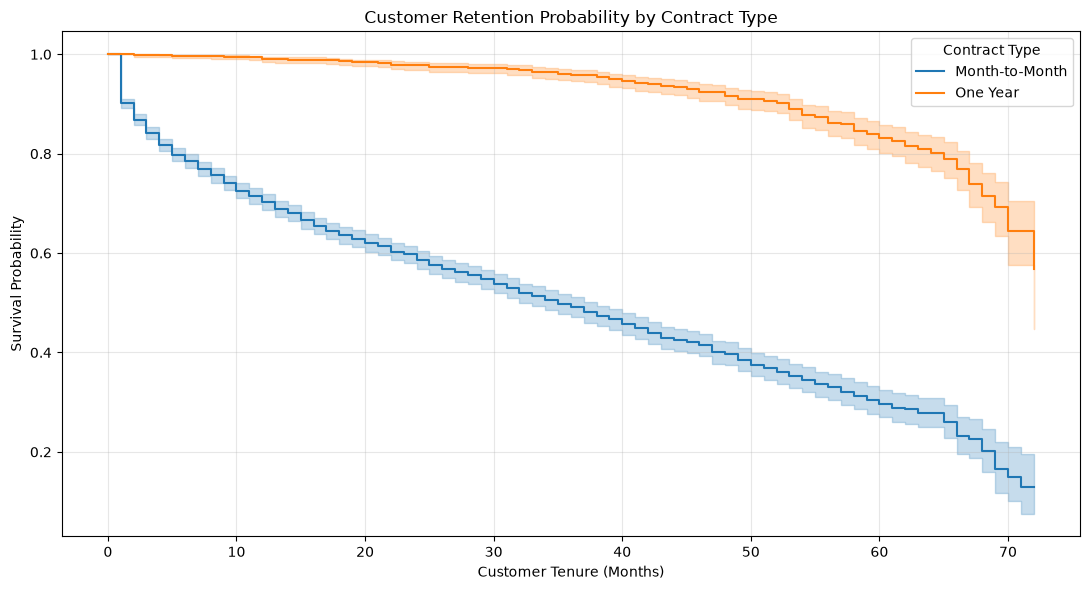

In [296]:

plt.figure(figsize=(11, 6))

kmf_m2m.plot_survival_function()
kmf_1yr.plot_survival_function()

plt.title('Customer Retention Probability by Contract Type')
plt.xlabel('Customer Tenure (Months)')
plt.ylabel('Survival Probability')
plt.grid(alpha=0.3)
plt.legend(title='Contract Type')
plt.tight_layout()
plt.show()

#### 11.6 Export Statistical Summary

In [297]:
# Create statistical summary from calculated test results
stat_summary = pd.DataFrame(chi2_results)

# Export results
stat_summary.to_csv(
    "telco_step3_statistical_summary.csv",
    index=False
)

print("\n" + "=" * 85)
print("STEP 3 COMPLETE: STATISTICAL ANALYSIS")
print("=" * 85)

print("\nStatistical Summary:")
print(stat_summary.to_string(index=False))

print("\nSaved statistical results to 'telco_step3_statistical_summary.csv'.")


STEP 3 COMPLETE: STATISTICAL ANALYSIS

Statistical Summary:
             Metric_Track  Test_Statistic       p_value  Degrees_of_Freedom  Statistical_Significance
       Chi2_contract_type     1184.596572 5.863038e-258                 2.0 Statistically Significant
    Chi2_internet_service      732.309590 9.571788e-160                 2.0 Statistically Significant
Chi2_is_automatic_payment      309.348557  3.027873e-69                 1.0 Statistically Significant
        Chi2_tech_support      190.166842  2.923567e-43                 1.0 Statistically Significant
             Welch_t_ARPU       18.407527  8.592449e-73                 NaN Statistically Significant

Saved statistical results to 'telco_step3_statistical_summary.csv'.


In [298]:
!pip install shap


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


### Section 12: Predictive Modeling: Customer Churn Risk

#### 12.1 Extract Features from SQL Warehouse

In [300]:

df_ml = df_stat.copy()
y = df_ml['churn_flag']

# Remove customer ID and target from predictors
X_raw = df_ml.drop(
    columns=['customer_id', 'churn_flag']
)

numerical_cols = [
    'tenure_months',
    'monthly_charges',
    'total_charges'
]

for col in numerical_cols:
    X_raw[col] = pd.to_numeric(
        X_raw[col],
        errors='coerce'
    )

if X_raw[numerical_cols].isna().any().any():
    raise ValueError("Missing or invalid numerical values found.")

# Encode categorical variables
X_encoded = pd.get_dummies(
    X_raw,
    drop_first=True,
    dtype=int
)

print(f"Encoded features: {X_encoded.shape[1]}")

Encoded features: 24


#### 12.2 Split Data into Training, Validation, and Testing Sets

In [301]:
print("\n--- PHASE 3: SPLITTING DATA ---")

# Separate the final test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Divide remaining data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print(f"Training records   : {len(X_train):,}")
print(f"Validation records : {len(X_val):,}")
print(f"Testing records    : {len(X_test):,}")


--- PHASE 3: SPLITTING DATA ---
Training records   : 4,225
Validation records : 1,409
Testing records    : 1,409


#### 12.3 Feature Scaling

In [302]:
print("\n--- PHASE 4: FEATURE SCALING ---")

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Fit scaler on training data only
X_train_scaled[numerical_cols] = scaler.fit_transform(
    X_train[numerical_cols]
)

# Transform validation and test data
X_val_scaled[numerical_cols] = scaler.transform(
    X_val[numerical_cols]
)

X_test_scaled[numerical_cols] = scaler.transform(
    X_test[numerical_cols]
)


--- PHASE 4: FEATURE SCALING ---


#### 12.6 Model Benchmarking

In [303]:
print("\n================ MODEL BENCHMARKING ================")

# Calculate class imbalance ratio from training data
scale_weight = (
    (len(y_train) - y_train.sum()) / y_train.sum()
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        max_depth=8
    ),

    "XGBoost Classifier": xgb.XGBClassifier(
        n_estimators=100,
        scale_pos_weight=scale_weight,
        eval_metric='logloss',
        random_state=42,
        max_depth=4,
        learning_rate=0.05
    )
}

best_model = None
best_auc = -1
best_model_name = ""

# Train and compare models
for name, model in models.items():

    # Logistic Regression uses scaled features.
    # Tree-based models use the original feature values.
    if name == "Logistic Regression":
        X_fit = X_train_scaled
        X_validate = X_val_scaled
    else:
        X_fit = X_train
        X_validate = X_val

    model.fit(X_fit, y_train)

    y_val_probs = model.predict_proba(
        X_validate
    )[:, 1]

    auc_score = roc_auc_score(
        y_val,
        y_val_probs
    )

    print(f"{name:22s} | Validation ROC-AUC: {auc_score:.4f}")

    if auc_score > best_auc:
        best_auc = auc_score
        best_model = model
        best_model_name = name

print("\nSelected Model:")
print(f"{best_model_name} | Validation ROC-AUC: {best_auc:.4f}")


================ MODEL BENCHMARKING ================
Logistic Regression    | Validation ROC-AUC: 0.8362
Random Forest          | Validation ROC-AUC: 0.8386
XGBoost Classifier     | Validation ROC-AUC: 0.8387

Selected Model:
XGBoost Classifier | Validation ROC-AUC: 0.8387


#### 12.7 Recall-Based Classification Threshold Selection

In [304]:
print("\n--- PHASE 6: THRESHOLD SELECTION ---")

TARGET_RECALL = 0.80

# the correct validation feature set
X_val_best = (
    X_val_scaled
    if best_model_name == "Logistic Regression"
    else X_val
)

y_val_probs_best = best_model.predict_proba(
    X_val_best
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    y_val_probs_best
)

# Identifying thresholds achieving the target recall
valid_indices = np.where(
    recalls[:-1] >= TARGET_RECALL
)[0]

if len(valid_indices) > 0:

    optimal_idx = valid_indices[-1]
    optimal_threshold = thresholds[optimal_idx]

else:

    optimal_threshold = 0.50

    print(
        "Warning: Target recall could not be achieved. "
        "Using 0.50 as the fallback threshold."
    )

# validation performance
y_val_pred = (
    y_val_probs_best >= optimal_threshold
).astype(int)

val_precision = precision_score(
    y_val,
    y_val_pred,
    zero_division=0
)

val_recall = recall_score(
    y_val,
    y_val_pred,
    zero_division=0
)

print(f"Selected threshold : {optimal_threshold:.4f}")
print(f"Validation precision: {val_precision:.2%}")
print(f"Validation recall   : {val_recall:.2%}")


--- PHASE 6: THRESHOLD SELECTION ---
Selected threshold : 0.4779
Validation precision: 48.62%
Validation recall   : 80.21%


#### 12.8 Final Evaluation on Untouched Test Data

In [305]:
print("\n--- PHASE 7: FINAL TEST SET EVALUATION ---")

X_test_best = (
    X_test_scaled
    if best_model_name == "Logistic Regression"
    else X_test
)

# Generate test probabilities
y_test_probs = best_model.predict_proba(
    X_test_best
)[:, 1]

# Apply selected threshold
y_test_pred = (
    y_test_probs >= optimal_threshold
).astype(int)

# Calculate performance metrics
test_auc = roc_auc_score(y_test, y_test_probs)

test_precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

print(f"Selected model : {best_model_name}")
print(f"Test ROC-AUC   : {test_auc:.4f}")
print(f"Test precision : {test_precision:.2%}")
print(f"Test recall    : {test_recall:.2%}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(f"True Negatives  : {test_cm[0, 0]}")
print(f"False Positives : {test_cm[0, 1]}")
print(f"False Negatives : {test_cm[1, 0]}")
print(f"True Positives  : {test_cm[1, 1]}")


--- PHASE 7: FINAL TEST SET EVALUATION ---
Selected model : XGBoost Classifier
Test ROC-AUC   : 0.8447
Test precision : 50.66%
Test recall    : 81.55%

Classification Report:
              precision    recall  f1-score   support

    Retained       0.91      0.71      0.80      1035
     Churned       0.51      0.82      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.81      0.74      0.75      1409


Confusion Matrix:
True Negatives  : 738
False Positives : 297
False Negatives : 69
True Positives  : 305


#### 12.9 SHAP Model Explainability

In [306]:
print("\n--- PHASE 8: SHAP FEATURE IMPORTANCE ---")

# Select appropriate explainer
if best_model_name == "Logistic Regression":

    background = X_train_scaled.sample(
        n=min(100, len(X_train_scaled)),
        random_state=42
    )

    explainer = shap.LinearExplainer(
        best_model,
        background
    )

    shap_input = X_test_scaled

else:

    explainer = shap.TreeExplainer(best_model)
    shap_input = X_test

# Calculate SHAP values
shap_values = explainer.shap_values(shap_input)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[1]

elif isinstance(shap_values, shap.Explanation):
    shap_values = shap_values.values

if len(shap_values.shape) == 3:
    shap_values = shap_values[:, :, 1]

# Calculate global feature importance
shap_importance = pd.DataFrame({
    'Feature': X_test_best.columns,
    'Mean_SHAP_Value': np.abs(shap_values).mean(axis=0)
}).sort_values(
    by='Mean_SHAP_Value',
    ascending=False
)

print("\nTop 5 Global Churn Drivers:")
print(shap_importance.head(5).to_string(index=False))


--- PHASE 8: SHAP FEATURE IMPORTANCE ---

Top 5 Global Churn Drivers:
                     Feature  Mean_SHAP_Value
      contract_type_Two year         0.646430
               tenure_months         0.461497
      contract_type_One year         0.301632
             monthly_charges         0.270615
internet_service_Fiber optic         0.269439


#### 12.10 Customer-Level Churn Probability and Risk Tiers

In [307]:
print("\n--- PHASE 9: CUSTOMER RISK SCORING ---")

# Retrieve original test customer records
df_test_scored = df_ml.loc[X_test.index].copy()

# Attach predicted churn probabilities
df_test_scored['P_Churn'] = y_test_probs

# Classify customers into risk tiers
df_test_scored['Risk_Tier'] = pd.cut(
    df_test_scored['P_Churn'],
    bins=[0, 0.35, 0.65, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk'],
    include_lowest=True
)

print("\nRisk Tier Distribution:")

print(
    df_test_scored['Risk_Tier'].value_counts(
        sort=False
    )
)


--- PHASE 9: CUSTOMER RISK SCORING ---

Risk Tier Distribution:
Risk_Tier
Low Risk       675
Medium Risk    332
High Risk      402
Name: count, dtype: int64


#### 12.11 Export Predictive Modeling Results

In [308]:
# Export scored test accounts
output_file = "telco_step4_scored_accounts.csv"

df_test_scored.to_csv(
    output_file,
    index=False
)

# Export SHAP feature importance
shap_importance.to_csv(
    "telco_shap_feature_importance.csv",
    index=False
)

print("\n" + "=" * 60)
print("STEP 4 COMPLETE: PREDICTIVE MODELING")
print("=" * 60)

print(f"Selected model       : {best_model_name}")
print(f"Final test ROC-AUC   : {test_auc:.4f}")
print(f"Selected threshold   : {optimal_threshold:.4f}")
print(f"Test precision       : {test_precision:.2%}")
print(f"Test recall          : {test_recall:.2%}")

print(f"\nExported customer scores: {output_file}")
print("Exported SHAP importance: telco_shap_feature_importance.csv")


STEP 4 COMPLETE: PREDICTIVE MODELING
Selected model       : XGBoost Classifier
Final test ROC-AUC   : 0.8447
Selected threshold   : 0.4779
Test precision       : 50.66%
Test recall          : 81.55%

Exported customer scores: telco_step4_scored_accounts.csv
Exported SHAP importance: telco_shap_feature_importance.csv


### 13 Financial Risk Analysis & Executive Retention Strategy

#### 13.1 Load and validate scored accounts

In [309]:

print("Loading scored accounts dataset...")

df_scored = pd.read_csv("telco_step4_scored_accounts.csv")

required_cols = [
    "customerID",
    "monthly_charges",
    "P_Churn"
]

missing_cols = [
    col for col in required_cols
    if col not in df_scored.columns
]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

if df_scored.empty:
    raise ValueError("Scored accounts dataset is empty.")

if df_scored["customerID"].duplicated().any():
    raise ValueError("Duplicate customer IDs detected.")

if df_scored[["monthly_charges", "P_Churn"]].isna().any().any():
    raise ValueError("Missing financial or probability values detected.")

if not df_scored["P_Churn"].between(0, 1).all():
    raise ValueError("Churn probabilities must be between 0 and 1.")

if (df_scored["monthly_charges"] < 0).any():
    raise ValueError("Negative monthly charges detected.")

print(f"Validated customers: {len(df_scored):,}")
print("Data validation completed successfully.")

Loading scored accounts dataset...


ValueError: Missing required columns: ['customerID']

#### 13.2 Probability-weighted revenue exposure

In [310]:

df_scored["Monthly_pCaR"] = (
    df_scored["P_Churn"] *
    df_scored["monthly_charges"]
)

df_scored["Annual_pCaR"] = (
    df_scored["Monthly_pCaR"] * 12
)

# financial measures
total_monthly_mrr = df_scored["monthly_charges"].sum()

total_annualized_revenue = total_monthly_mrr * 12

portfolio_monthly_pcar = df_scored["Monthly_pCaR"].sum()

portfolio_annual_pcar = df_scored["Annual_pCaR"].sum()

# Calculate probability-weighted exposure as a percentage of MRR
exposure_percentage = (
    portfolio_monthly_pcar / total_monthly_mrr * 100
    if total_monthly_mrr > 0 else 0
)


print("--- PORTFOLIO FINANCIAL RISK ---")

print(f"Scored Test-Sample Size       : {len(df_scored):,}")
print(f"Total Monthly MRR             : ${total_monthly_mrr:,.2f}")
print(f"Annualized Recurring Revenue  : ${total_annualized_revenue:,.2f}")
print(f"Monthly pCaR Exposure         : ${portfolio_monthly_pcar:,.2f}")
print(f"Annualized pCaR Exposure      : ${portfolio_annual_pcar:,.2f}")
print(f"Monthly Exposure / MRR        : {exposure_percentage:.2f}%")

--- PORTFOLIO FINANCIAL RISK ---
Scored Test-Sample Size       : 1,409
Total Monthly MRR             : $90,301.20
Annualized Recurring Revenue  : $1,083,614.40
Monthly pCaR Exposure         : $41,423.37
Annualized pCaR Exposure      : $497,080.46
Monthly Exposure / MRR        : 45.87%


#### 13.3 High-risk / high-value customer segmentation

In [311]:

CHURN_RISK_CUTOFF = 0.60

median_bill = df_scored["monthly_charges"].median()

# Identify high-risk and high-value customers
high_risk_mask = (
    (df_scored["P_Churn"] >= CHURN_RISK_CUTOFF) &
    (df_scored["monthly_charges"] >= median_bill)
)

df_target = df_scored.loc[high_risk_mask].copy()


target_count = len(df_target)

target_exposure = df_target["Annual_pCaR"].sum()

target_share = (
    target_exposure / portfolio_annual_pcar * 100
    if portfolio_annual_pcar > 0 else 0
)

target_population_share = (
    target_count / len(df_scored) * 100
    if len(df_scored) > 0 else 0
)


print("--- TARGET CUSTOMER SEGMENT ---")

print(f"Churn Probability Cutoff : {CHURN_RISK_CUTOFF:.0%}")
print(f"Median Monthly Charges   : ${median_bill:.2f}")
print(f"Target Customers         : {target_count:,}")
print(f"Share of Portfolio       : {target_population_share:.2f}%")
print(f"Target Annual pCaR       : ${target_exposure:,.2f}")
print(f"Share of Total Exposure  : {target_share:.2f}%")

--- TARGET CUSTOMER SEGMENT ---
Churn Probability Cutoff : 60%
Median Monthly Charges   : $69.95
Target Customers         : 359
Share of Portfolio       : 25.48%
Target Annual pCaR       : $288,132.93
Share of Total Exposure  : 57.97%


#### 13.4 Retention campaign scenario analysis

In [312]:

MONTHLY_DISCOUNT = 10.00
MONTHLY_SUPPORT_SUBSIDY = 5.00

MONTHLY_INCENTIVE = (
    MONTHLY_DISCOUNT +
    MONTHLY_SUPPORT_SUBSIDY
)

ANNUAL_INCENTIVE = MONTHLY_INCENTIVE * 12

ASSUMED_RELATIVE_CHURN_REDUCTION = 0.35

# Estimate post-intervention churn probabilities
df_target["Post_Intervention_P_Churn"] = (
    df_target["P_Churn"] *
    (1 - ASSUMED_RELATIVE_CHURN_REDUCTION)
)

# Calculate baseline annualized exposure
df_target["Baseline_Annual_Exposure"] = (
    df_target["P_Churn"] *
    df_target["monthly_charges"] * 12
)

# Calculate post-intervention annualized exposure
df_target["Post_Intervention_Annual_Exposure"] = (
    df_target["Post_Intervention_P_Churn"] *
    df_target["monthly_charges"] * 12
)

# Estimate potentially preserved revenue
df_target["Estimated_Preserved_Revenue"] = (
    df_target["Baseline_Annual_Exposure"] -
    df_target["Post_Intervention_Annual_Exposure"]
)

# Calculate annual retention cost per customer
df_target["Annual_Retention_Cost"] = ANNUAL_INCENTIVE

# Calculate estimated net financial gain
df_target["Net_Financial_Gain"] = (
    df_target["Estimated_Preserved_Revenue"] -
    df_target["Annual_Retention_Cost"]
)

print("Retention intervention assumptions applied.")

Retention intervention assumptions applied.


#### 13.5 Campaign financial performance and ROI

In [313]:

total_retention_spend = (
    df_target["Annual_Retention_Cost"].sum()
)

# Calculate estimated preserved revenue
total_preserved_revenue = (
    df_target["Estimated_Preserved_Revenue"].sum()
)


net_campaign_gain = (
    total_preserved_revenue -
    total_retention_spend
)


benefit_cost_ratio = (
    total_preserved_revenue / total_retention_spend
    if total_retention_spend > 0 else np.nan
)


net_roi = (
    (net_campaign_gain / total_retention_spend) * 100
    if total_retention_spend > 0 else np.nan
)


print("--- RETENTION CAMPAIGN PERFORMANCE ---")

print(f"Annual Campaign Cost        : ${total_retention_spend:,.2f}")
print(f"Estimated Preserved Revenue : ${total_preserved_revenue:,.2f}")
print(f"Net Financial Gain          : ${net_campaign_gain:,.2f}")
print(f"Benefit-to-Cost Ratio       : {benefit_cost_ratio:.2f}x")
print(f"Net Campaign ROI            : {net_roi:.2f}%")

--- RETENTION CAMPAIGN PERFORMANCE ---
Annual Campaign Cost        : $64,620.00
Estimated Preserved Revenue : $100,846.53
Net Financial Gain          : $36,226.53
Benefit-to-Cost Ratio       : 1.56x
Net Campaign ROI            : 56.06%


#### 13.6 Risk prioritization and Revenue Protection Action Plan

In [316]:
# targeted customers by annualized pCaR
df_target_sorted = df_target.sort_values(
    by="Annual_pCaR",
    ascending=False
).copy()


output_cols = [
    "customer_id",
    "contract_type",
    "internet_service",
    "monthly_charges",
    "P_Churn",
    "Annual_pCaR",
    "Post_Intervention_P_Churn",
    "Estimated_Preserved_Revenue",
    "Annual_Retention_Cost",
    "Net_Financial_Gain"
]


action_file = "telco_step5_retention_action.csv"

df_target_sorted[output_cols].to_csv(
    action_file,
    index=False
)

print(f"Action File Exported: {action_file}")

Action File Exported: telco_step5_retention_action.csv


#### 13.7 Export complete financial risk portfolio

In [317]:

portfolio_file = "telco_step5_financial_risk_portfolio.csv"

df_scored.to_csv(
    portfolio_file,
    index=False
)

print(f"Financial Risk Portfolio exported: {portfolio_file}")
print("FINANCIAL RISK ANALYSIS COMPLETE")


Financial Risk Portfolio exported: telco_step5_financial_risk_portfolio.csv
FINANCIAL RISK ANALYSIS COMPLETE
